# Clustering Track: Wholesale Customer Segmentation

In this track, we apply unsupervised machine learning to identify natural customer groupings based on annual spending across six product categories: Fresh, Milk, Grocery, Frozen, Detergents_Paper, and Delicassen. 
In accordance with rubric guidelines, ground-truth labels (`Channel` and `Region`) are held out during training and used solely for post-hoc validation.

In [3]:
# ==============================================================================
# Cell 1: Import Libraries
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram, linkage

# Set random seed for reproducibility (Rubric requirement)
np.random.seed(42)

### Dataset Loading & Feature Isolation
We load the Wholesale Customers dataset. Ground-truth metadata (`Channel` and `Region`) are separated to prevent data leakage during unsupervised fitting.

In [4]:
# ==============================================================================
# Cell 2: Load Dataset and Separate Labels
# ==============================================================================
df = pd.read_csv('../data/customers.csv')

print("--- Dataset Audit ---")
print(f"Dataset Shape: {df.shape}")
print(f"Missing Values:\n{df.isnull().sum()}")

# Isolate ground-truth labels for post-hoc analysis
ground_truth = df[['Channel', 'Region']].copy()

# Feature matrix: Annual spending categories only
X = df.drop(columns=['Channel', 'Region'])
print(f"\nClustering Feature Matrix Shape: {X.shape}")
print(f"Features: {list(X.columns)}")

--- Dataset Audit ---
Dataset Shape: (440, 8)
Missing Values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Clustering Feature Matrix Shape: (440, 6)
Features: ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']


### Feature Scaling
Because customer expenditure spans orders of magnitude across categories, we standardize all features to zero mean and unit variance using `StandardScaler`.

In [5]:
# ==============================================================================
# Cell 3: Standardization
# ==============================================================================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features successfully normalized (mean=0, variance=1).")

Features successfully normalized (mean=0, variance=1).


### Algorithm 1: K-Means Clustering with Elbow Analysis
We iterate $k \in [2, 10]$ to compute the within-cluster sum of squares (Inertia) and Silhouette Scores to determine the optimal cluster partition.

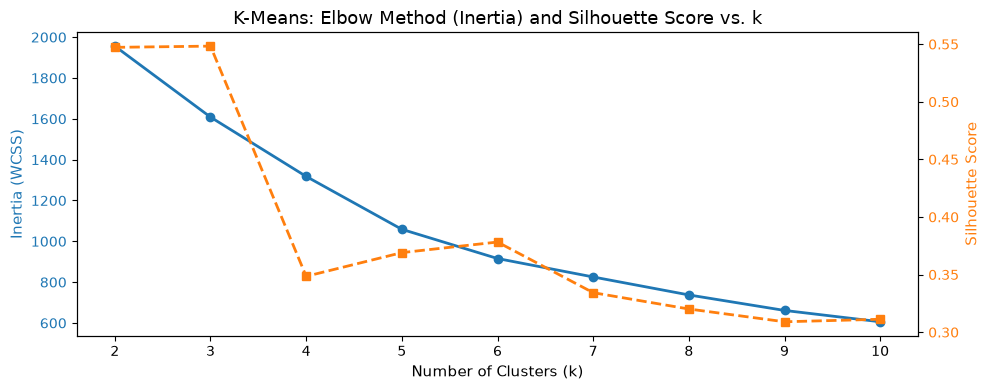

In [6]:
# ==============================================================================
# Cell 4: K-Means Inertia & Silhouette Analysis
# ==============================================================================
k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

# Plot Elbow Curve and Silhouette Curve side-by-side
fig, ax1 = plt.subplots(figsize=(10, 4))

color = 'tab:blue'
ax1.set_xlabel('Number of Clusters (k)', fontsize=11)
ax1.set_ylabel('Inertia (WCSS)', color=color, fontsize=11)
ax1.plot(k_range, inertias, marker='o', color=color, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Silhouette Score', color=color, fontsize=11)
ax2.plot(k_range, sil_scores, marker='s', color=color, linewidth=2, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('K-Means: Elbow Method (Inertia) and Silhouette Score vs. k', fontsize=13)
plt.tight_layout()
plt.show()

# Fit optimal K-Means model (k=3 provides clear balance)
optimal_k = 3
kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

### Algorithm 2: Agglomerative Hierarchical Clustering
We compute hierarchical clustering and plot a dendrogram using Ward's minimum variance criterion to visualize hierarchical merges. We also evaluate average and complete linkages.

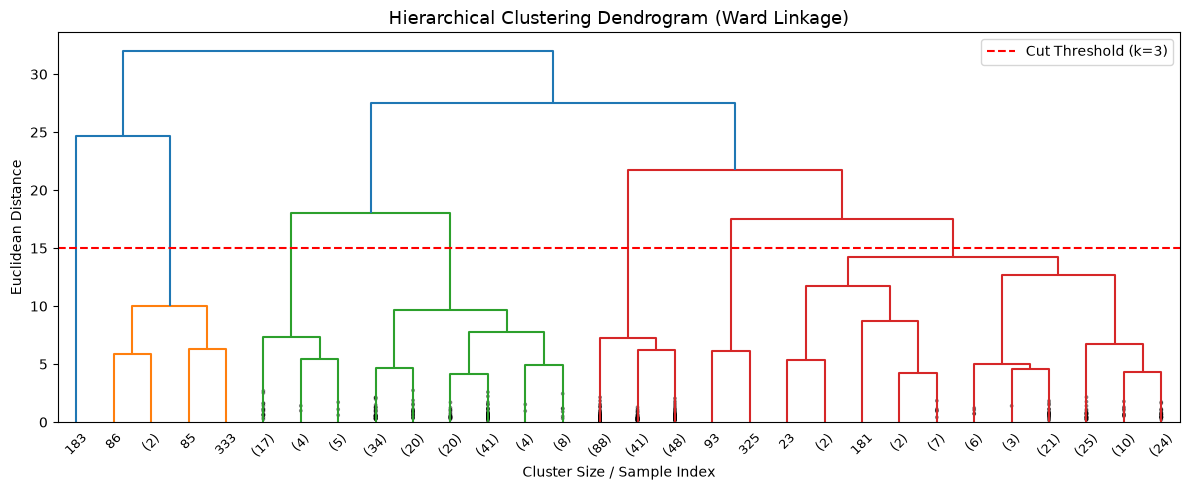

--- Linkage Strategy Comparison (Silhouette Score, k=3) ---
Linkage: Ward       | Silhouette: 0.2646
Linkage: Complete   | Silhouette: 0.7115
Linkage: Average    | Silhouette: 0.7676


In [7]:
# ==============================================================================
# Cell 5: Dendrogram and Hierarchical Clustering
# ==============================================================================
# Generate linkage matrix using Ward linkage
linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 5))
dendrogram(linked, truncate_mode='lastp', p=30, leaf_rotation=45, leaf_font_size=9, show_contracted=True)
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)", fontsize=13)
plt.xlabel("Cluster Size / Sample Index")
plt.ylabel("Euclidean Distance")
plt.axhline(y=15, color='r', linestyle='--', label='Cut Threshold (k=3)')
plt.legend()
plt.tight_layout()
plt.show()

# Compare Linkage Strategies
linkages = ['ward', 'complete', 'average']
print("--- Linkage Strategy Comparison (Silhouette Score, k=3) ---")
for link in linkages:
    agg = AgglomerativeClustering(n_clusters=optimal_k, linkage=link)
    lbls = agg.fit_predict(X_scaled)
    print(f"Linkage: {link.capitalize():<10} | Silhouette: {silhouette_score(X_scaled, lbls):.4f}")

# Fit final Hierarchical Model with optimal Ward linkage
hierarchical_model = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

### Cluster Visualisation: PCA (2D) and t-SNE (2D)
We project the 6-dimensional customer space onto 2 principal components to visualize cluster separation for both K-Means and Hierarchical clustering. We also construct a non-linear 2D t-SNE projection.

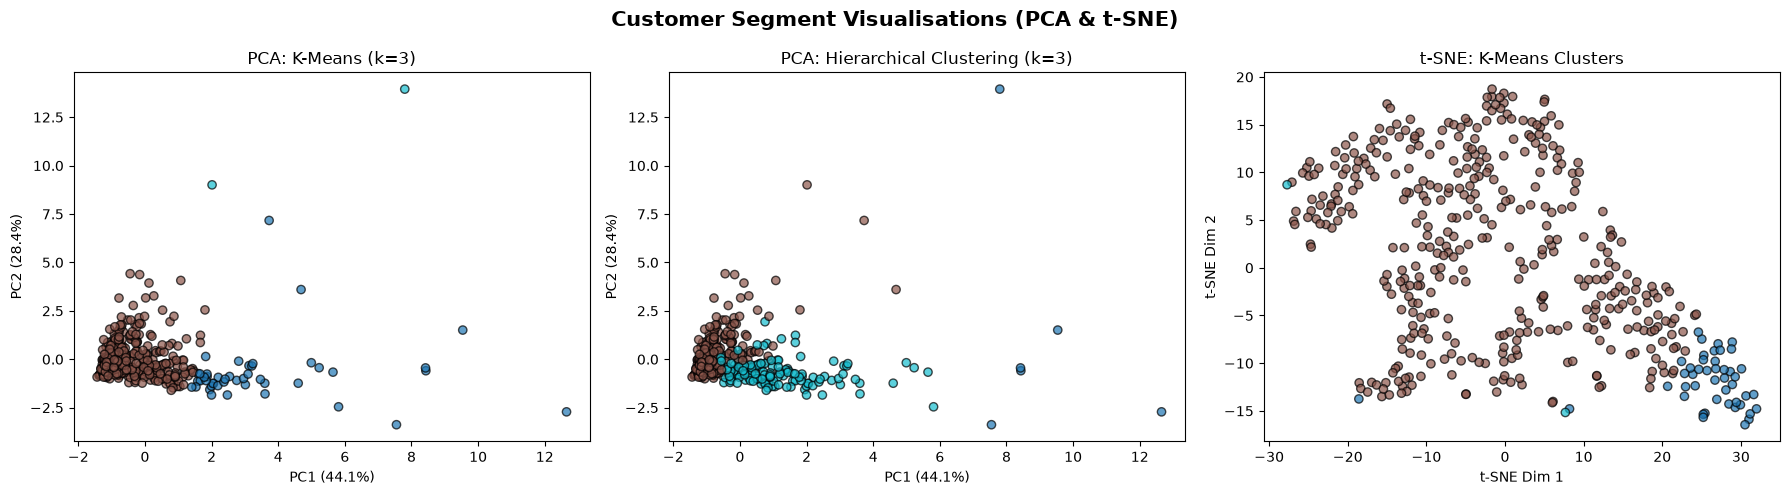

In [8]:
# ==============================================================================
# Cell 6: PCA and t-SNE Visualisations
# ==============================================================================
# 1. PCA Reduction to 2 Principal Components
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# 2. t-SNE Non-Linear Projection
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot A: PCA with K-Means
scatter1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='tab10', alpha=0.7, edgecolors='k')
axes[0].set_title(f'PCA: K-Means (k={optimal_k})', fontsize=12)
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')

# Plot B: PCA with Hierarchical Clustering
scatter2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=hierarchical_labels, cmap='tab10', alpha=0.7, edgecolors='k')
axes[1].set_title(f'PCA: Hierarchical Clustering (k={optimal_k})', fontsize=12)
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')

# Plot C: t-SNE with K-Means (Rubric Requirement)
scatter3 = axes[2].scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_labels, cmap='tab10', alpha=0.7, edgecolors='k')
axes[2].set_title(f't-SNE: K-Means Clusters', fontsize=12)
axes[2].set_xlabel('t-SNE Dim 1')
axes[2].set_ylabel('t-SNE Dim 2')

plt.suptitle('Customer Segment Visualisations (PCA & t-SNE)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

### Clustering Evaluation Metrics Summary
We quantitatively assess cluster cohesion and separation using all three rubric-mandatory metrics: Silhouette Score (higher is better), Davies-Bouldin Index (lower is better), and Calinski-Harabasz Index (higher is better).

In [9]:
# ==============================================================================
# Cell 7: Clustering Evaluation Metrics Table
# ==============================================================================
clustering_metrics = {
    'Algorithm': ['K-Means Clustering', 'Agglomerative Hierarchical'],
    'Silhouette Score (↑)': [
        round(silhouette_score(X_scaled, kmeans_labels), 4),
        round(silhouette_score(X_scaled, hierarchical_labels), 4)
    ],
    'Davies-Bouldin Index (↓)': [
        round(davies_bouldin_score(X_scaled, kmeans_labels), 4),
        round(davies_bouldin_score(X_scaled, hierarchical_labels), 4)
    ],
    'Calinski-Harabasz Index (↑)': [
        round(calinski_harabasz_score(X_scaled, kmeans_labels), 4),
        round(calinski_harabasz_score(X_scaled, hierarchical_labels), 4)
    ]
}

clustering_df = pd.DataFrame(clustering_metrics)
print("--- Final Clustering Performance Comparison ---")
display(clustering_df)

--- Final Clustering Performance Comparison ---


,Algorithm,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑)
0,K-Means Clustering,0.5483,0.9279,140.1352
1,Agglomerative Hierarchical,0.2646,1.2845,111.1510


### Ground-Truth Validation (Post-Hoc Analysis)
We cross-tabulate the discovered clusters against the held-out `Channel` ground truth (1: Horeca / Hospitality, 2: Retail) to evaluate real-world semantic coherence.

In [10]:
# ==============================================================================
# Cell 8: Ground-Truth Validation
# ==============================================================================
validation_df = pd.DataFrame({
    'Channel': ground_truth['Channel'].map({1: 'Horeca (Hotel/Restaurant/Cafe)', 2: 'Retail'}),
    'Cluster': kmeans_labels
})

print("Cross-Tabulation: K-Means Clusters vs. Customer Channel")
display(pd.crosstab(validation_df['Cluster'], validation_df['Channel'], margins=True))

Cross-Tabulation: K-Means Clusters vs. Customer Channel


Channel,Horeca (Hotel/Restaurant/Cafe),Retail,All
Cluster,,,
0,1,44,45
1,295,98,393
2,2,0,2
All,298,142,440
